# Understanding the Insider Landscape

Joshua Vu

Stats C161 — exploratory notes

**Question:** What distinguishes the publicly identified insider wallets from the other wallets in this sample?

These are descriptive comparisons. `confirmed=False` means the wallet has no confirmed label in this dataset. The sample comes from buyers in five selected event groups, rather than the full prediction-market population.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project whether VS Code starts the kernel here or in eda_output.
ROOT = Path.cwd()
while not (ROOT / "L3_prediction_markets_student_package_2026-10-07").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Start the notebook from the Project folder")
    ROOT = ROOT.parent
DATA = ROOT / "L3_prediction_markets_student_package_2026-10-07/notebooks/data"
w_feat = pd.read_csv(DATA / "wallet_features.csv")
w_scores = pd.read_csv(DATA / "wallet_scores.csv")
sns.set_theme(style="whitegrid", palette=["#3469A8", "#C05245"])
labels = {False: "Other / unconfirmed", True: "Confirmed"}


## 1. What is in the sample?
One row represents one wallet. Before comparing groups, check sample sizes and basic data quality.

In [2]:
print(f"Wallets: {len(w_feat):,}")
display(w_feat["confirmed"].value_counts().rename(index=labels).to_frame("wallets"))
print("Missing values:", w_feat.isna().sum().sum())
print("Duplicate wallet IDs:", w_feat.wallet.duplicated().sum())
display(w_feat.head(3))

Wallets: 55,952


,wallets
confirmed,
Other / unconfirmed,55933
Confirmed,19


Missing values: 0
Duplicate wallet IDs: 0


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
0,w_b6640fc6a7,6,1,241.805798,0.576023,1.000000,88.320,0.000322,1.598889,0.365252,False
1,w_ce85723407,6,4,33.230088,0.936964,0.405506,12.475,0.000362,49.930856,1.501651,False
2,w_b92e826e83,7,4,43.640110,0.340639,0.483274,12.000,0.000021,17.895579,1.099906,False


**Thoughts:** There are only 19 confirmed wallets out of 55,952. Every confirmed wallet changes a group percentage by about 5.3 percentage points, so individual cases matter. The confirmed labels are an incomplete set of known cases.

## 2. Which features look different?
Compare medians first because trade amounts have very large outliers.

In [3]:
features = ["trade_count", "unique_markets", "total_notional", "max_single_buy",
            "wallet_age_days", "concentration", "avg_buy_price",
            "market_notional_ratio", "position_anomaly_ratio"]
medians = w_feat.groupby("confirmed")[features].median().T
medians.columns = ["Other / unconfirmed", "Confirmed"]
display(medians.round(3))

,Other / unconfirmed,Confirmed
trade_count,10.000,155.000
unique_markets,4.000,8.000
total_notional,197.619,42668.076
max_single_buy,63.894,6400.000
wallet_age_days,20.841,11.461
concentration,0.527,0.415
avg_buy_price,0.733,0.661
market_notional_ratio,0.000,0.011
position_anomaly_ratio,1.557,0.827


**Thoughts:** Size looks like the strongest difference. The median confirmed wallet has about $42,668 in traded notional, compared with $198 for other wallets. Its largest buy is $6,400, compared with $64. Traded notional is trading activity, not profit.

Concentration goes in a less obvious direction: the confirmed median is lower. This makes me question whether “insiders only trade one market” is a useful general rule.

## 3. Is the size difference visible across the distribution?
Use a log scale transformation so small and large wallets can appear on the same chart. Each group gets its own percentage denominator.

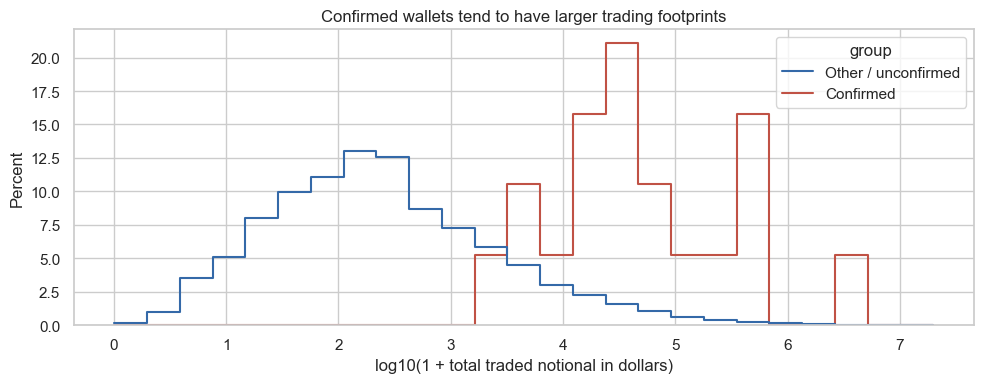

In [4]:
plot_data = w_feat.assign(
    group=w_feat.confirmed.map(labels),
    log_notional=np.log10(1 + w_feat.total_notional)
)
plt.figure(figsize=(10, 4))
sns.histplot(data=plot_data, x="log_notional", hue="group", bins=25,
             stat="percent", common_norm=False, element="step", fill=False)
plt.xlabel("log10(1 + total traded notional in dollars)")
plt.title("Confirmed wallets tend to have larger trading footprints")
plt.tight_layout()
plt.show()

**Thoughts:** The difference is visible beyond a comparison of means. All 19 confirmed wallets exceed the other group's median notional. A possible explanation is discovery bias: large visible traders may be more likely to attract public attention. This dataset cannot establish that explanation.

## 4. Are insider wallets younger or older?
The mean and median give different answers here.

,count,mean,median,min,max
confirmed,,,,,
Other / unconfirmed,55933,47.73,20.84,0.0,362.62
Confirmed,19,94.09,11.46,0.0,300.51


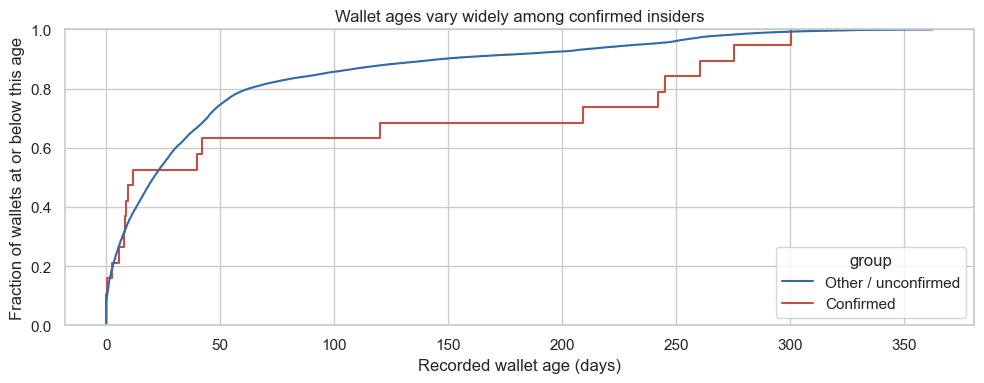

In [5]:
display(w_feat.groupby("confirmed").wallet_age_days
        .agg(["count", "mean", "median", "min", "max"]).rename(index=labels).round(2))
plt.figure(figsize=(10, 4))
sns.ecdfplot(data=plot_data, x="wallet_age_days", hue="group")
plt.xlabel("Recorded wallet age (days)")
plt.ylabel("Fraction of wallets at or below this age")
plt.title("Wallet ages vary widely among confirmed insiders")
plt.tight_layout()
plt.show()

**Thoughts:** The confirmed mean is 94 days versus 48, but the median is 11 days versus 21. So my initial “insiders are older” interpretation was too broad. Some confirmed wallets have long histories and others have very short histories. A recorded age of zero does not by itself prove a newly created blockchain address.

## 5. What do the individual insider wallets look like?
With 19 positive labels, looking at individual rows is manageable.

In [6]:
insiders = w_feat.loc[w_feat.confirmed].sort_values("total_notional", ascending=False)
display(insiders[["wallet", "trade_count", "unique_markets", "total_notional",
                  "max_single_buy", "wallet_age_days"]].round(2))
print("Largest wallet's share of all confirmed notional:",
      f"{insiders.total_notional.max() / insiders.total_notional.sum():.1%}")

,wallet,trade_count,unique_markets,total_notional,max_single_buy,wallet_age_days
20983,w_5b2b2d0846,3753,68,3900380.99,62847.89,275.29
18651,w_2a43266bd8,1332,55,675486.92,49900.00,300.51
17114,w_b484b941ed,677,26,489359.21,87427.82,245.00
45220,w_bc876cca82,742,22,359435.59,9910.00,41.89
30878,w_bae5b984cf,870,13,297220.77,36014.96,39.85
36341,w_651e7829e2,178,8,105116.36,9939.55,241.94
6257,w_cd38860893,155,2,75327.42,7909.98,2.25
2411,w_d1a074f023,199,6,65325.71,8412.96,208.95
24407,w_bf68f8e7eb,134,9,46028.97,3686.46,5.69
42221,w_45933e3f6b,136,3,42668.08,6400.00,9.53


Largest wallet's share of all confirmed notional: 63.0%


**Thoughts:** One wallet accounts for about 63% of the confirmed group's traded notional. Group means can hide this imbalance. The smallest confirmed wallet has about $1,865 notional, seven trades and one market, so the known insiders do not all have the same footprint.

## 6. Which way of ordering wallets finds more known insiders?

Suppose we can examine only a small fraction of the wallets. Which wallets should we look at first?

We compare three ways of sorting the **same 55,668 wallets**:

- **Anomaly score (`score`):** highest supplied model score first. Higher scores indicate more unusual feature combinations.
- **Total notional (`total_notional`):** largest total dollar amount traded first.
- **Largest buy (`max_single_buy`):** largest single purchase first.

For each ordering, keep the first 1%, 5% or 10% of wallets and count how many have a confirmed insider label. These percentages refer to **all wallets in the scored table**, not to the insiders.

**Example:** The top 5% contains 2,784 wallets. Sorting by total notional puts **13 known insiders** in that group. Sorting by anomaly score puts **5 known insiders** in its group. The lists can overlap, but they need not contain the same wallets.

There are **18 confirmed insiders in this comparison**. Part 7 explains why one of the original 19 is absent. We use the provided scores here and do not fit a new model.

Scored wallets: 55668 Confirmed: 18


Ranking,max_single_buy,score,total_notional
Top fraction,,,
1%,3,1,5
5%,14,5,13
10%,16,8,16


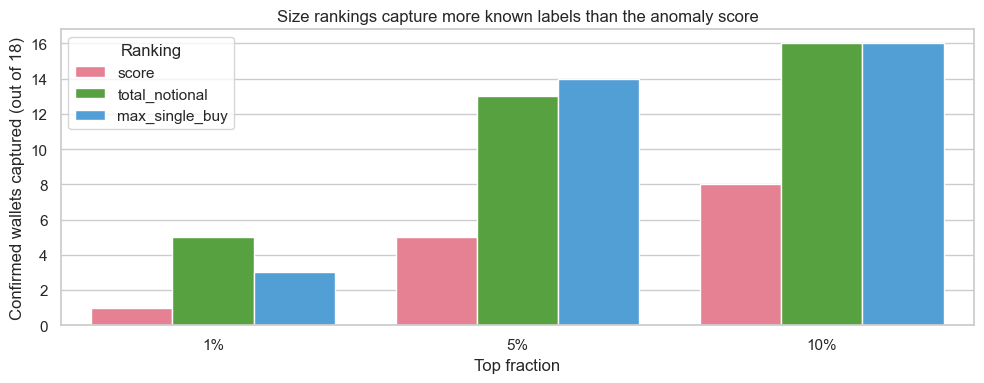

In [7]:
rows = []
for fraction in [0.01, 0.05, 0.10]:
    # Number of wallets we keep from each sorted list.
    k = int(np.ceil(len(w_scores) * fraction))
    for feature in ["score", "total_notional", "max_single_buy"]:
        # nlargest keeps the k highest values of this feature.
        # Summing True/False labels counts known insiders in that list.
        hits = int(w_scores.nlargest(k, feature).confirmed.sum())
        rows.append({"Top fraction": f"{fraction:.0%}", "Ranking": feature,
                     "Known insiders captured": hits})
comparison = pd.DataFrame(rows)
print("Scored wallets:", len(w_scores), "Confirmed:", int(w_scores.confirmed.sum()))
display(comparison.pivot(index="Top fraction", columns="Ranking",
                         values="Known insiders captured").reindex(["1%", "5%", "10%"]))
plt.figure(figsize=(10, 4))
sns.barplot(data=comparison, x="Top fraction", y="Known insiders captured", hue="Ranking")
plt.ylabel("Confirmed wallets captured (out of 18)")
plt.title("Size rankings capture more known labels than the anomaly score")
plt.tight_layout()
plt.show()

**Thoughts:** At the same review size of 2,784 wallets, sorting by total notional finds 13 of the 18 known insiders. Sorting by the largest buy finds 14, while sorting by anomaly score finds five. The chart's bar height is this count, so a taller bar means more known insiders appear in the selected list.

This suggests that simple trading-size measures are useful baselines for this sample. An unusual wallet is not necessarily an insider, and a known insider may resemble many ordinary traders.

These results do not show that every selected wallet is an insider: even the notional list contains 2,771 wallets without a confirmed label. This is an exploratory comparison on existing labels, with no held-out evaluation.

## 7. Why are there only 18 insiders in the score file?
Check which feature-table wallets are absent from the score table.

In [8]:
excluded = w_feat.loc[~w_feat.wallet.isin(w_scores.wallet)]
print("Excluded wallets:", len(excluded))
print("Confirmed wallets excluded:", int(excluded.confirmed.sum()))
display(excluded.loc[excluded.confirmed,
        ["wallet", "trade_count", "unique_markets", "total_notional"]])

Excluded wallets: 284
Confirmed wallets excluded: 1


,wallet,trade_count,unique_markets,total_notional
20983,w_5b2b2d0846,3753,68,3.900381e+06


**Thoughts:** The excluded confirmed wallet is also the largest, with $3.90 million in traded notional and 3,753 trades. It crosses the demo's 2,000-trade bot threshold. That is a useful preprocessing concern: a high-activity rule can filter out a known insider. The rule itself does not verify that a wallet is automated.

## 8. Where could entertainment fit?
The local catalog keyword screen found **1,216 candidate markets across 208 event groups**, with **457 matching resolution records**. Keywords included box office, Oscars, Grammys, Spotify, Billboard and Emmys. This is a preliminary inventory requiring manual review, not a count of entertainment insiders.

**Thoughts / next questions:**
- For resolved box-office markets, do unusually large buys precede public information releases?
- Does the same wallet repeat that pattern across different releases?
- Do the patterns remain unusual relative to other traders in the same market?

The demo uses `w_` pseudonyms, while the downloaded trades use `0x` addresses and a later time period. A mapping would be needed to attach these insider labels to those trades. Announcement timestamps would also need verification.

## Main observations

The clearest pattern in this sample is the size of the trading footprint. Wallet age is mixed, and high concentration does not characterize every known insider. Simple size rankings capture more known labels than the supplied anomaly score. The exclusion of the largest insider also shows why preprocessing needs examination.

**Limits:** Only 19 labels, selected event groups, possible public-discovery bias, unknown status of the other wallets and features calculated over available trading history. These findings motivate follow-up questions rather than establish a general detection method.

**Sources:** Student package `README.md` and `insider_demo.ipynb` for sample and model descriptions. `wallet_features.csv` and `wallet_scores.csv` for calculations. Local catalog parquet files for the entertainment inventory. The expanded notebook in `eda_output/insider_eda.ipynb` contains the inventory query and additional diagnostics.